# Part 1: Explore

What has happened in Formula 1 since 1950, in four charts: pole position (1.1), retirements (1.2), dominant teams (1.3) and grid vs. finish (1.4). Reads `data/processed/results_joined.csv`, so run `01_build_dataset.ipynb` first.

The Indianapolis 500 (1950–1960) is left out here and in Part 2. It counted for the championship, but it was a separate American race with its own drivers.

## 1.1 How often does pole position turn into a win, by driver and by decade?



In [16]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/processed/results_joined.csv", low_memory=False)

# Leave out the Indianapolis 500 (1950-1960): it counted for the championship,
# but it was a separate American race with its own drivers
df = df[~df["indy500"]].copy()

In [17]:
# Only the pole sitters (grid 1), and how many rows that is

poles = df[df["pole"]]
len(poles)

1168

In [18]:
# Share of pole sitters who went on to win, per decade
# Some 1950s races (and the 1964 US GP) have 2-3 pole rows because drivers shared cars,
# so count each race once: a win if any of its pole rows won
pole_races = poles.groupby(["raceId", "decade"])["won"].any().reset_index()
by_decade = pole_races.groupby("decade")["won"].mean() * 100
by_decade.round(1)

decade
1950    44.6
1960    37.4
1970    36.8
1980    28.2
1990    42.6
2000    50.0
2010    50.5
2020    56.7
Name: won, dtype: float64

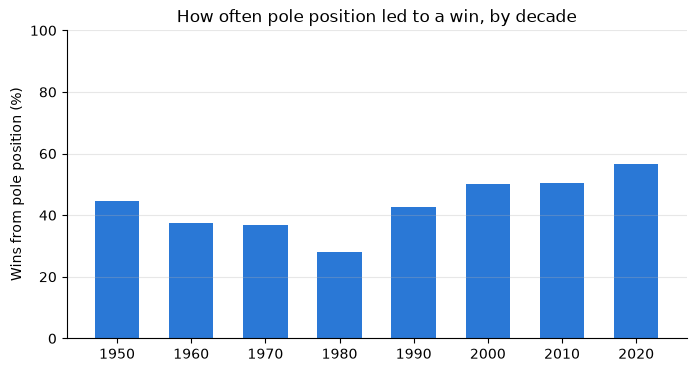

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decade.index.astype(str), by_decade.values, color="#2a78d6", width=0.6)
ax.set_title("How often pole position led to a win, by decade")
ax.set_ylabel("Wins from pole position (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In the 1950s, 44.6% of pole starts ended in a win, and about 37% in the 1960s and 1970s.
The 1980s stand out at 28.2%, much lower than the decades around them.
After the 1980s, the win rate from pole rises every decade and peaks in the 2020s at 56.7%.

In [20]:
# For each driver: how many poles, how many wins from pole, and the rate
# drop_duplicates: Jim Clark has two pole rows in the 1964 US GP (he took over a teammate's car), so count it once
driver_poles = poles.drop_duplicates(["raceId", "driver"])
by_driver = driver_poles.groupby("driver").agg(poles=("won", "size"), wins=("won", "sum"))
by_driver["win_rate"] = (by_driver["wins"] / by_driver["poles"] * 100).round(1)

# Only drivers with at least 15 poles, best rate first
by_driver[by_driver["poles"] >= 15].sort_values("win_rate", ascending=False)

,poles,wins,win_rate
driver,,,
Max Verstappen,50,39,78.0
Fernando Alonso,22,14,63.6
Michael Schumacher,68,40,58.8
Lewis Hamilton,105,61,58.1
Alain Prost,33,18,54.5
Sebastian Vettel,57,31,54.4
Nigel Mansell,32,17,53.1
Lando Norris,19,10,52.6
Nico Rosberg,30,15,50.0


Among drivers with at least 15 poles, the five best at turning pole into a win are Max Verstappen, Fernando Alonso, Michael Schumacher, Lewis Hamilton and Alain Prost. Verstappen leads at 78.0%, 14.4 percentage points ahead of Alonso in second. Lewis Hamilton has the most pole starts of any driver, with 105.

## 1.2 How have retirements (crashes, mechanical failures) changed since the 1950s?

In [21]:
# Starters who could retire: drivers who actually started ("started" from 01),
# minus those disqualified or excluded after the race, which isn't a retirement
starters = df[df["started"] & ~df["status"].isin(["Disqualified", "Excluded"])]
len(df), len(starters)



(25886, 25464)

In [22]:
# Share of starters who did NOT finish, per decade
finish_rate = starters.groupby("decade")["finished"].mean() * 100
retire_rate = 100 - finish_rate
retire_rate.round(1)

decade
1950    48.2
1960    45.4
1970    45.2
1980    51.8
1990    46.3
2000    29.5
2010    17.5
2020    12.4
Name: finished, dtype: float64

In [23]:
# Statuses that count as a crash
crash = ["Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Damage", "Debris"]

# Statuses that are neither a crash nor clearly the car breaking
other = ["Retired", "Not classified", "Lapped", "Not restarted", "Stalled",
         "Physical", "Injury", "Injured", "Eye injury", "Illness", "Driver unwell",
         "Safety", "Safety concerns", "Safety belt", "Underweight",
         "Out of fuel", "Fuel rig", "Refuelling", "Puncture", "Tyre"]

# Give back "Crash", "Other" or "Mechanical" for one status
def retirement_type(status):
    if status in crash:
        return "Crash"
    elif status in other or status.startswith("+"):
        return "Other"
    else:
        return "Mechanical"

# Quick test on three examples
retirement_type("Engine"), retirement_type("Collision"), retirement_type("+3 Laps")

('Mechanical', 'Crash', 'Other')

In [24]:
# Only the starters who did NOT finish
retired = starters[~starters["finished"]].copy()

# Run retirement_type on every row's status and store the answer in a new column
retired["reason"] = retired["status"].apply(retirement_type)

retired["reason"].value_counts()

reason
Mechanical    5955
Crash         2510
Other          659
Name: count, dtype: int64

In [25]:
# Only use years where the retirement reason was recorded
known_retired = retired[retired["year"] <= 2022]
known_starters = starters[starters["year"] <= 2022]

# Count retirements: one row per decade, one column per reason
counts = pd.crosstab(known_retired["decade"], known_retired["reason"])

# How many starters in each decade
starts = known_starters.groupby("decade").size()

# Turn counts into "% of starters"
rates = counts.div(starts, axis=0) * 100
rates.round(1)

reason,Crash,Mechanical,Other
decade,,,
1950,6.9,39.1,2.2
1960,6.1,36.7,2.6
1970,11.6,30.4,3.2
1980,12.7,36.6,2.6
1990,16.6,28.6,1.2
2000,10.8,17.3,1.3
2010,6.6,9.3,1.5
2020,6.7,6.5,0.6


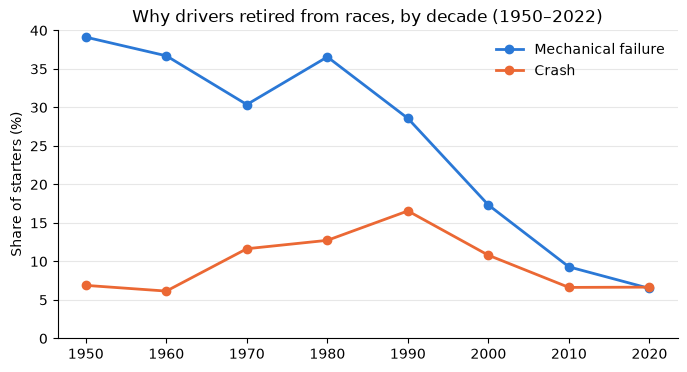

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rates.index, rates["Mechanical"], marker="o", linewidth=2, color="#2a78d6", label="Mechanical failure")
ax.plot(rates.index, rates["Crash"], marker="o", linewidth=2, color="#eb6834", label="Crash")
ax.set_title("Why drivers retired from races, by decade (1950–2022)")
ax.set_ylabel("Share of starters (%)")
ax.set_xticks(rates.index)
ax.set_ylim(0, 40)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In the 1950s almost half of all starters (48.2%) failed to finish a race; by the 2020s only 12.4% did.
Most of that drop comes from mechanical failures, which fell from 39.1% of starters in the 1950s to 6.5% in 2020–2022.
Crashes went the other way at first, peaking at 16.6% in the 1990s, before falling to 6.7%, so today crashes and mechanical failures are about equally common.

## 1.3 Which teams dominated each era?


In [27]:
# Only the rows where the driver won the race
winners = df[df["won"]].copy()

# Old team names include the engine maker ("Lotus-Climax", "Lotus-Ford").
# "team_group" (from 01) keeps only the part before the "-", so each team counts as one
winners["team"] = winners["team_group"]

# Three 1950s races have two winner rows because two drivers shared the winning car. Count each win once
winners = winners.drop_duplicates(["raceId", "team"])

# Count wins for each team in each decade
team_wins = winners.groupby(["decade", "team"]).size()

# How many races were held in each decade
races = df.groupby("decade")["raceId"].nunique()

# Turn win counts into "% of that decade's races"
win_share = team_wins.div(races, level="decade") * 100

# Keep the 3 teams with the highest share in each decade
top3 = win_share.groupby(level="decade", group_keys=False).nlargest(3)
top3.round(1)

decade  team      
1950    Ferrari       39.2
        Alfa Romeo    13.5
        Maserati      12.2
1960    Lotus         36.4
        Ferrari       13.1
        BRM           12.1
1970    Ferrari       25.7
        Lotus         24.3
        Tyrrell       14.6
1980    McLaren       35.9
        Williams      23.7
        Ferrari       11.5
1990    Williams      37.7
        McLaren       26.5
        Ferrari       17.3
2000    Ferrari       48.9
        McLaren       23.6
        Renault       11.5
2010    Mercedes      47.0
        Red Bull      28.3
        Ferrari       14.1
2020    Red Bull      47.3
        Mercedes      27.3
        McLaren       15.3
dtype: float64

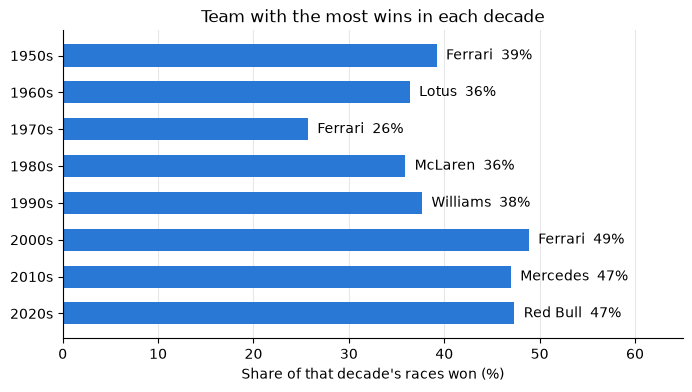

In [28]:
# Just the #1 team in each decade
top1 = top3.groupby(level="decade").head(1)

# Turn the two-part label (decade, team) back into normal columns
top1 = top1.reset_index(name="share")

fig, ax = plt.subplots(figsize=(8, 4))
labels = top1["decade"].astype(str) + "s"
ax.barh(labels, top1["share"], height=0.6, color="#2a78d6")

# Write the team name and % at the end of each bar
for i, row in top1.iterrows():
    ax.text(row["share"] + 1, i, f'{row["team"]}  {row["share"]:.0f}%', va="center")

ax.invert_yaxis()
ax.set_title("Team with the most wins in each decade")
ax.set_xlabel("Share of that decade's races won (%)")
ax.set_xlim(0, 65)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


Ferrari is the only team to lead more than one decade (the 1950s, 1970s and 2000s); each other decade had a different leader.
Dominance has grown stronger: before 2000 the top team won 26–39% of a decade's races, but since 2000 it has won 47–49% (Ferrari, then Mercedes, then Red Bull).
The 1970s were the most open decade, with Ferrari (26%) only just ahead of Lotus (24%).
Note: the 2020s only cover 2020–2026 so far, and decades are a rough cut for eras. For example, Red Bull won 41 races from 2010 to 2013, before Mercedes took over in 2014.

## 1.4 Grid position vs. finish: scatter plots by decade



In [29]:
# Only drivers who finished and started from a real grid spot (grid 0 = started from the pit lane)
finishers = df[df["finished"] & (df["grid"] > 0)].copy()

# Rank grid and finish within each race, among that race's finishers. When cars retire, the finishers'
# positions have gaps (1st, 2nd, 5th, 9th ...). Ranking closes them (1st, 2nd, 3rd, 4th), so retirements
# don't lower the score on their own. 3.1 scores the model the same way

# One number per decade: how closely finish order follows grid order
# (1 = the same order in every race, 0 = no connection at all)
finishers["grid_rank"] = finishers.groupby("raceId")["grid"].rank()
finishers["finish_rank"] = finishers.groupby("raceId")["position"].rank()

def grid_finish_link(d):
    return d["grid_rank"].corr(d["finish_rank"])

link = finishers.groupby("decade").apply(grid_finish_link)
link.round(2)

decade
1950    0.78
1960    0.71
1970    0.70
1980    0.71
1990    0.80
2000    0.77
2010    0.80
2020    0.76
dtype: float64

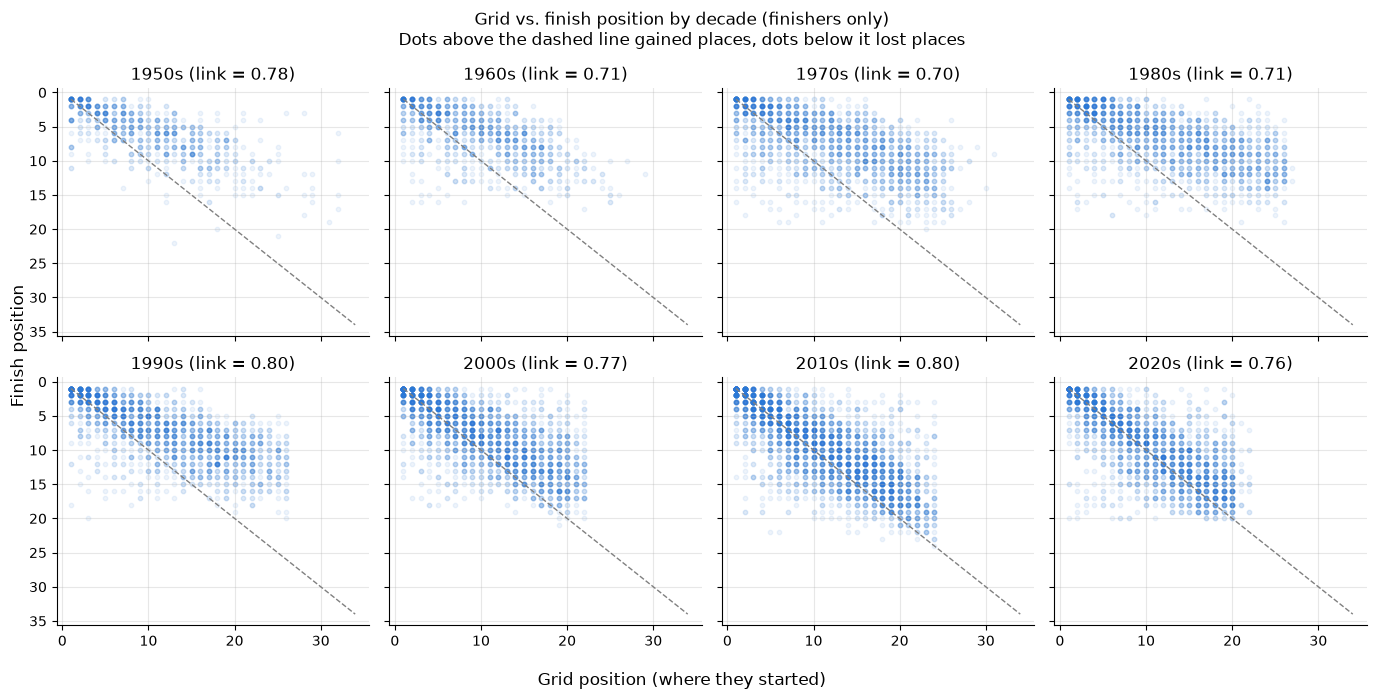

In [30]:
decades = sorted(finishers["decade"].unique())

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)

for ax, decade in zip(axes.flat, decades):
    d = finishers[finishers["decade"] == decade]
    ax.scatter(d["grid"], d["position"], s=10, alpha=0.08, color="#2a78d6")
    ax.plot([1, 34], [1, 34], color="gray", linewidth=1, linestyle="--")
    ax.set_title(f"{decade}s (link = {link[decade]:.2f})")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].invert_yaxis()
fig.supxlabel("Grid position (where they started)")
fig.supylabel("Finish position")
fig.suptitle("Grid vs. finish position by decade (finishers only)\nDots above the dashed line gained places, dots below it lost places")
plt.tight_layout()
plt.show()

Where a driver starts has always mattered: the link between grid and finish order was 0.70–0.78 in the 1950s–1980s and 0.76–0.80 from the 1990s onward. The link ranks grid and finish within each race, so retirements don't lower it on their own.
Up to the 1990s most dots sit above the dashed line, because so many cars retired (see 1.2) that anyone who kept going moved up the order.
Since the 2000s, with far fewer retirements, the dots hug the dashed line, so most finishers end up close to where they started.